In [9]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

from utils import load_data

plt.rcParams["figure.figsize"] = (10, 5)
load_data.clear()

df = load_data("data/activities_clean.csv").copy()
print(f"df : {len(df)} sorties, {len(df.columns)} colonnes")

2026-10-13 22:57:43.025 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


df : 131 sorties, 30 colonnes


In [10]:
# Features engineered
df["pause_ratio"] = df["pause_seconds"] / df["moving_time_seconds"]
df["elev_per_km"] = df["total_elevation_gain_m"] / df["distance_km"]

# Trier par date pour les rolling backward
df["date_utc"] = pd.to_datetime(df["start_date_local"], utc=True)
df = df.sort_values("date_utc").reset_index(drop=True)
df["date_only"] = df["date_utc"].dt.floor("D").dt.tz_localize(None)

def rolling_backward(dates, values, days):
    out = np.zeros(len(dates))
    for i in range(len(dates)):
        mask = (dates.values < dates.values[i]) & (dates.values >= dates.values[i] - pd.Timedelta(days=days))
        out[i] = values[mask].sum()
    return out

df["vol_30d_km"] = rolling_backward(df["date_only"], df["distance_km"], 30)
df["days_since_last"] = df["date_only"].diff().dt.days.astype(float)

# Saison (facteur) : pour l'instant on ne la met pas, on commence simple
# df["season"] = df["date_only"].dt.month.map({12:"hiver",1:"hiver",2:"hiver",3:"printemps",...})

print(df[["distance_km", "pace_min_km", "elev_per_km", "pause_ratio",
          "weather_temperature", "weather_humidity",
          "vol_30d_km", "days_since_last"]].describe().round(2))

       distance_km  pace_min_km  elev_per_km  pause_ratio  \
count       131.00       131.00       131.00       131.00   
mean          5.36         5.00         6.27         0.06   
std           4.79         0.79         7.79         0.27   
min           0.29         3.63         0.00         0.00   
25%           2.37         4.40         3.26         0.00   
50%           4.73         4.85         4.24         0.00   
75%           6.36         5.33         5.76         0.02   
max          35.38         7.14        48.99         2.47   

       weather_temperature  weather_humidity  vol_30d_km  days_since_last  
count               131.00            131.00      131.00           130.00  
mean                 16.35             71.08       35.48             6.68  
std                   5.90             14.90       30.23            10.25  
min                   0.20             32.00        0.00             0.00  
25%                  13.50             60.50        9.55             1

Filtres + échantillon de modélisation

In [11]:
# Mêmes filtres que l'ACP v4 : exclut micro-sorties et le long trail
mask = (df["distance_km"] >= 1) & (df["distance_km"] < 30)
dfm = df[mask].copy()

# Check NA sur les variables du modèle
MODEL_VARS = ["pace_min_km", "weather_temperature", "weather_humidity",
              "distance_km", "elev_per_km", "vol_30d_km", "days_since_last"]
print("NA par variable :")
print(dfm[MODEL_VARS].isna().sum())
print(f"\nn modélisation : {len(dfm.dropna(subset=MODEL_VARS))} (sur {len(dfm)})")

NA par variable :
pace_min_km            0
weather_temperature    0
weather_humidity       0
distance_km            0
elev_per_km            0
vol_30d_km             0
days_since_last        1
dtype: int64

n modélisation : 121 (sur 122)


Modèle OLS complet

In [12]:
# T° en polynôme degré 2, humidité séparée
# On ne met PAS season pour l'instant : à discuter avec Quost (confondu avec T° et vol_30d)
formula = (
    "pace_min_km ~ weather_temperature + I(weather_temperature**2) "
    "+ weather_humidity + distance_km + elev_per_km "
    "+ vol_30d_km + days_since_last"
)

model = smf.ols(formula, data=dfm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.182
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     3.581
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00162
Time:                        22:57:43   Log-Likelihood:                -131.93
No. Observations:                 121   AIC:                             279.9
Df Residuals:                     113   BIC:                             302.2
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

VIF (colinéarité)

In [13]:
# VIF sur les prédicteurs (hors intercept, hors terme polynomial)
# On ajoute T² à la main pour voir le VIF du polynôme
X = dfm[["weather_temperature", "weather_humidity", "distance_km",
         "elev_per_km", "vol_30d_km", "days_since_last"]].dropna().copy()
X["T2"] = X["weather_temperature"]**2
X = sm.add_constant(X)

vif = pd.DataFrame({
    "var": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif.round(2))

                   var     VIF
0                const  104.56
1  weather_temperature   13.40
2     weather_humidity    1.88
3          distance_km    1.06
4          elev_per_km    1.09
5           vol_30d_km    1.38
6      days_since_last    1.32
7                   T2   13.61


Diagnostics résidus

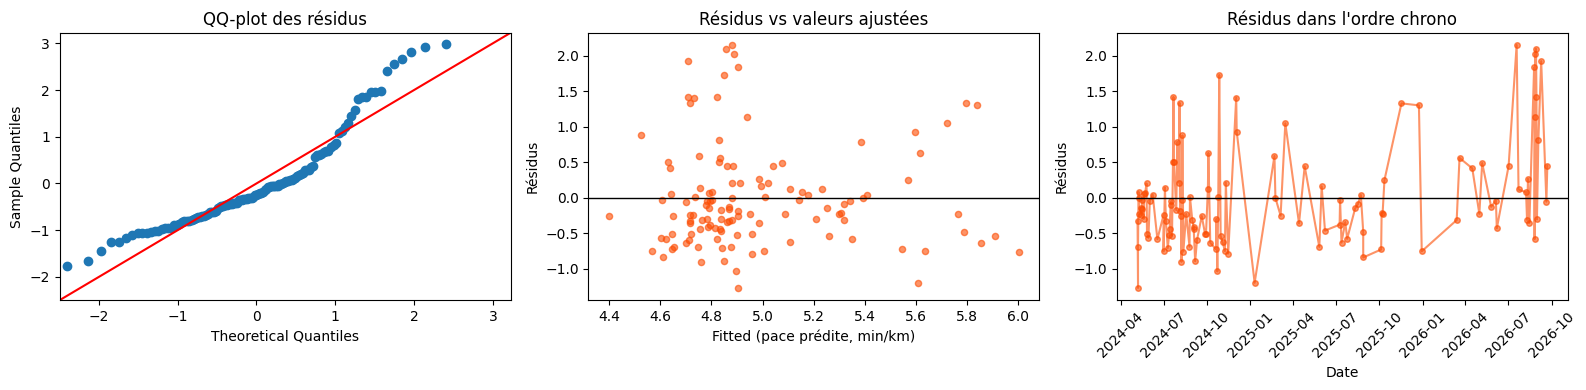


Durbin-Watson : 1.545  (2 = pas d'autocorrelation)
R² ajusté : 0.131
RMSE pace : 0.745 min/km = 44.7 s/km


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# QQ-plot
sm.qqplot(model.resid, line="45", fit=True, ax=axes[0])
axes[0].set_title("QQ-plot des résidus")

# Résidus vs fitted
axes[1].scatter(model.fittedvalues, model.resid, alpha=0.6, s=20, color="#FC4C02")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Fitted (pace prédite, min/km)")
axes[1].set_ylabel("Résidus")
axes[1].set_title("Résidus vs valeurs ajustées")

# Résidus dans l'ordre chrono
dfm_fit = dfm.loc[model.model.data.row_labels].copy()
dfm_fit["resid"] = model.resid.values
dfm_fit_sorted = dfm_fit.sort_values("date_only")
axes[2].plot(dfm_fit_sorted["date_only"], dfm_fit_sorted["resid"], "o-",
             alpha=0.6, markersize=4, color="#FC4C02")
axes[2].axhline(0, color="black", lw=1)
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Résidus")
axes[2].set_title("Résidus dans l'ordre chrono")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(f"\nDurbin-Watson : {durbin_watson(model.resid):.3f}  (2 = pas d'autocorrelation)")
print(f"R² ajusté : {model.rsquared_adj:.3f}")
print(f"RMSE pace : {np.sqrt(model.mse_resid):.3f} min/km = {np.sqrt(model.mse_resid)*60:.1f} s/km")

Bootstrap sur l’optimum T°

Bootstrap : 997/1000 tirages valides (parabole convexe)
Optimum ponctuel : 15.73 °C
IC bootstrap 95 % (percentile) : [6.97, 20.38] °C
Médiane bootstrap : 15.29 °C


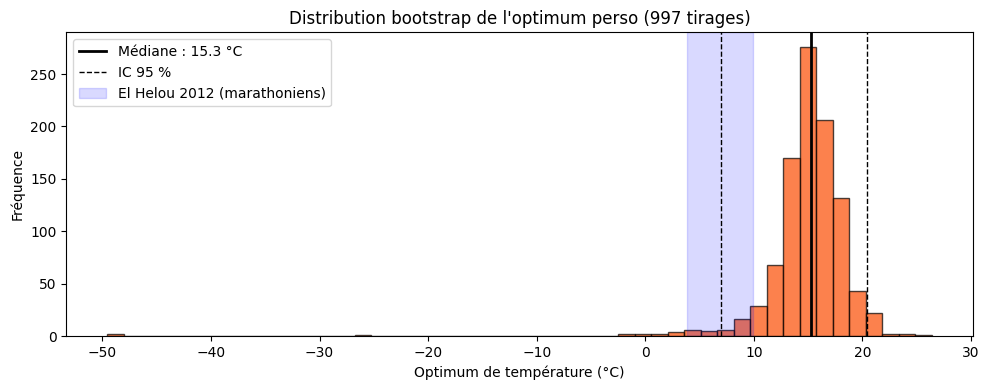

In [ ]:
from scipy import stats

rng = np.random.default_rng(42)
N_BOOT = 1000
n = len(dfm)

optima = np.zeros(N_BOOT)
for b in range(N_BOOT):
    idx = rng.integers(0, n, size=n)
    sample = dfm.iloc[idx]
    try:
        m = smf.ols(formula, data=sample).fit()
        b1 = m.params["weather_temperature"]
        b2 = m.params["I(weather_temperature ** 2)"]
        if b2 > 0:  # parabole convexe → vrai minimum
            optima[b] = -b1 / (2 * b2)
        else:
            optima[b] = np.nan
    except Exception:
        optima[b] = np.nan

optima = optima[~np.isnan(optima)]
print(f"Bootstrap : {len(optima)}/{N_BOOT} tirages valides (parabole convexe)")
print(f"Optimum ponctuel : {-model.params['weather_temperature'] / (2*model.params['I(weather_temperature ** 2)']):.2f} °C")
print(f"IC bootstrap 95 % (percentile) : [{np.percentile(optima, 2.5):.2f}, {np.percentile(optima, 97.5):.2f}] °C")
print(f"Médiane bootstrap : {np.median(optima):.2f} °C")

# Histogramme de la distribution bootstrap
fig, ax = plt.subplots(figsize=(10, 4))
# Bornes robustes : 1er et 99e percentile étendus
x_lo = min(0, np.percentile(optima, 1) - 2)
x_hi = np.percentile(optima, 99) + 2
ax.hist(optima, bins=np.linspace(x_lo, x_hi, 60), color="#FC4C02",
        alpha=0.7, edgecolor="black")
ax.axvline(np.median(optima), color="black", lw=2,
           label=f"Médiane : {np.median(optima):.1f} °C")
ax.axvline(np.percentile(optima, 2.5), color="black", lw=1, ls="--",
           label=f"IC 95 %: [{np.percentile(optima, 2.5):.1f}, {np.percentile(optima, 97.5):.1f}]")
ax.axvline(np.percentile(optima, 97.5), color="black", lw=1, ls="--")
ax.axvspan(3.8, 9.9, alpha=0.15, color="blue",
           label="El Helou 2012 (marathoniens, 3.8-9.9 °C)")
ax.set_xlim(x_lo, x_hi)
ax.set_xlabel("Optimum de température (°C)")
ax.set_ylabel("Fréquence (bootstrap)")
ax.set_title(f"Distribution bootstrap de l'optimum perso ({len(optima)} tirages)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Cook’s distance (outliers influents)

Seuil Cook's distance : 0.0328

8 sorties les plus influentes :
 date_only                            name  distance_km  pace_min_km  weather_temperature  elev_per_km  fitted  resid  cooks_d
2025-12-24          Course à pied matinale        4.623        7.138                  0.2        3.396   5.838  1.300    0.135
2026-08-27         Course à pied en soirée        2.423        6.907                 19.9        6.397   4.888  2.019    0.095
2025-01-10           Course à pied du midi        1.811        4.409                  2.2        8.119   5.608 -1.199    0.073
2025-11-17 Course à pied dans l'après-midi        2.188        7.123                  5.2       22.446   5.795  1.328    0.071
2024-08-12           Course à pied le soir       12.017        5.243                 31.8        3.695   6.001 -0.759    0.067
2024-12-03           Course à pied de nuit        1.100        6.528                  1.6        6.362   5.598  0.930    0.054
2025-03-16          Course à pied matinale     

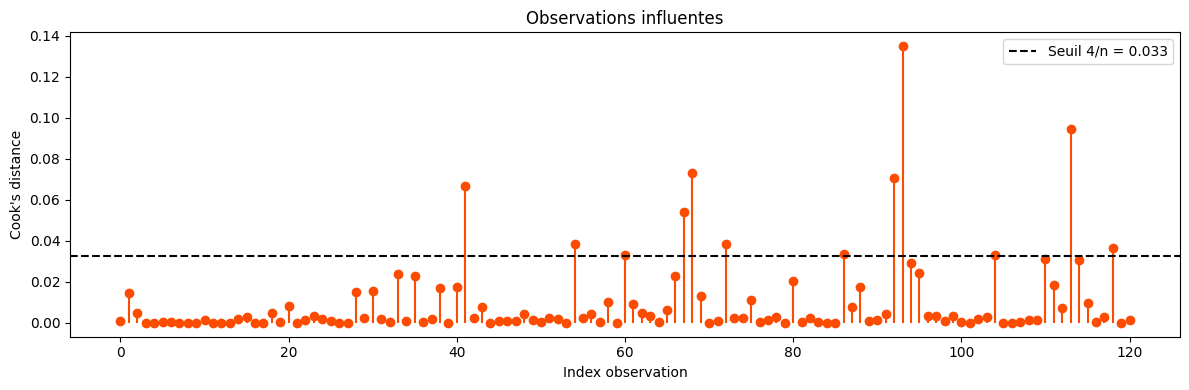

In [16]:
from statsmodels.stats.outliers_influence import OLSInfluence

infl = OLSInfluence(model)
cooks_d = infl.cooks_distance[0]

# Seuil usuel : 4/n
seuil = 4 / len(dfm)
dfm_fit = dfm.loc[model.model.data.row_labels].copy()
dfm_fit["cooks_d"] = cooks_d
dfm_fit["resid"] = model.resid.values
dfm_fit["fitted"] = model.fittedvalues.values

top_influents = dfm_fit.nlargest(8, "cooks_d")[
    ["date_only", "name", "distance_km", "pace_min_km",
     "weather_temperature", "elev_per_km", "fitted", "resid", "cooks_d"]
]
print(f"Seuil Cook's distance : {seuil:.4f}")
print(f"\n8 sorties les plus influentes :")
print(top_influents.round(3).to_string(index=False))

# Figure Cook's distance
fig, ax = plt.subplots(figsize=(12, 4))
ax.stem(range(len(cooks_d)), cooks_d, basefmt=" ", linefmt="#FC4C02", markerfmt="o")
ax.axhline(seuil, color="black", ls="--", label=f"Seuil 4/n = {seuil:.3f}")
ax.set_xlabel("Index observation")
ax.set_ylabel("Cook's distance")
ax.set_title("Observations influentes")
ax.legend()
plt.tight_layout()
plt.show()